# TP2 — Apache Spark Core
## RDD clé/valeur et analyse de ventes
**Compte rendu et notebook exécuté**

**Anwar Ezzirani · G4 · 5IIR · Data Science & AI**  
**Date : 2 novembre 2026**  
Énoncé : `TP2_RDD_Ventes.pdf` · Spark 4.0.0 · Python · JupyterLab · Docker.

Ce document traite tous les exercices des parties 0 à 6. Pour chaque exercice :
prévision avant calcul, commande exécutée, résultat réel et interprétation.
Les captures de Spark UI et les mesures de shuffle proviennent de cette exécution.
Les erreurs de `zip` sont provoquées volontairement et interceptées.
Les montants sont exprimés en dirhams (MAD), sauf conversion explicite en euros.

## Partie 0 — Environnement et données
**Prévision.** Une session `local[4]` fournit quatre threads. Le fichier comporte
23 lignes avec l'en-tête, soit 22 enregistrements dont trois invalides.
Le dossier `data` est relatif au notebook et reste utilisable dans un autre JupyterLab.
Le conteneur utilise `/home/jovyan/work`, équivalent au dossier partagé du guide.

In [1]:
from pathlib import Path
from datetime import datetime
import os, sys, json, time, platform, requests
from operator import add
from IPython.display import display, Image, Markdown
# Le noyau de certaines images Jupyter expose Spark via SPARK_HOME.
spark_home = os.environ.get("SPARK_HOME")
if spark_home:
    spark_python = Path(spark_home) / "python"
    for chemin in [spark_python, *spark_python.glob("lib/py4j-*-src.zip")]:
        if str(chemin) not in sys.path:
            sys.path.insert(0, str(chemin))
    os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
from pyspark.sql import SparkSession

ROOT = Path.cwd()
DATA = ROOT / "data"
ART = ROOT / "artifacts"
CAP = ART / "captures"
for folder in (DATA, ART, CAP, ART / "spark-events"):
    folder.mkdir(parents=True, exist_ok=True)

spark = (SparkSession.builder.master("local[4]").appName("TP2-Anwar-Ezzirani-G4")
         .config("spark.ui.port", "4040")
         .config("spark.eventLog.enabled", "true")
         .config("spark.eventLog.compress", "false")
         .config("spark.eventLog.dir", (ART / "spark-events").as_uri())
         .getOrCreate())
sc = spark.sparkContext
sc.setLogLevel("OFF")  # Les exceptions attendues sont affichées explicitement en 4.3.
RESULTATS = {}
print("Étudiant : Anwar Ezzirani | G4 | 5IIR Data Science & AI")
print("Exécution UTC :", datetime.now().astimezone().isoformat())
print("Python :", platform.python_version(), "| Spark :", spark.version)
print("Java :", sc._jvm.java.lang.System.getProperty("java.version"))
print("Master :", sc.master, "| Parallélisme :", sc.defaultParallelism)
print("Spark UI :", sc.uiWebUrl)
assert spark.version == "4.0.0" and sc.master == "local[4]"

Étudiant : Anwar Ezzirani | G4 | 5IIR Data Science & AI
Exécution UTC : 2026-11-02T12:00:01.537864+00:00
Python : 3.13.5 | Spark : 4.0.0
Java : 17.0.16
Master : local[4] | Parallélisme : 4
Spark UI : http://25257f41ac0a:4040


In [2]:
lignes = 'id,date,ville,produit,quantite,prix\n1,2025-01-05,Casablanca,Laptop,2,9500\n2,2025-01-06,Rabat,Telephone,5,3200\n3,2025-01-07,Casablanca,Telephone,3,3200\n4,2025-01-09,Fes,Tablette,4,2800\n5,2025-01-11,Rabat,Laptop,1,9500\n6,2025-01-12,Marrakech,Tablette,6,2800\n7,2025-01-15,Casablanca,Souris,20,120\n8,2025-01-16,Fes,Laptop,2,9500\n9,2025-01-18,Marrakech,Telephone,4,3200\n10,2025-01-20,Rabat,Souris,15,120\n11,2025-01-21,Agadir,Clavier,10,250\n12,ligne_corrompue\n13,2025-01-22,Casablanca,Tablette,2,abc\n14,2025-01-25,Fes,Souris,30,120\n15,2025-01-26,Agadir,Clavier,8,250\n16,2025-01-27,Casablanca,Clavier,12,250\n17,2025-02-02,Rabat,Telephone,2,3200\n18,2025-02-03,Agadir,Laptop,1,9500\n19,2025-02-04,Marrakech,Souris,,120\n20,2025-02-05,Rabat,Tablette,3,2800\n21,2025-02-07,Marrakech,Laptop,2,9500\n22,2025-02-09,Fes,Clavier,5,250'
(DATA / "ventes.csv").write_text(lignes + "\n", encoding="utf-8")
print((DATA / "ventes.csv").read_text(encoding="utf-8"))

id,date,ville,produit,quantite,prix
1,2025-01-05,Casablanca,Laptop,2,9500
2,2025-01-06,Rabat,Telephone,5,3200
3,2025-01-07,Casablanca,Telephone,3,3200
4,2025-01-09,Fes,Tablette,4,2800
5,2025-01-11,Rabat,Laptop,1,9500
6,2025-01-12,Marrakech,Tablette,6,2800
7,2025-01-15,Casablanca,Souris,20,120
8,2025-01-16,Fes,Laptop,2,9500
9,2025-01-18,Marrakech,Telephone,4,3200
10,2025-01-20,Rabat,Souris,15,120
11,2025-01-21,Agadir,Clavier,10,250
12,ligne_corrompue
13,2025-01-22,Casablanca,Tablette,2,abc
14,2025-01-25,Fes,Souris,30,120
15,2025-01-26,Agadir,Clavier,8,250
16,2025-01-27,Casablanca,Clavier,12,250
17,2025-02-02,Rabat,Telephone,2,3200
18,2025-02-03,Agadir,Laptop,1,9500
19,2025-02-04,Marrakech,Souris,,120
20,2025-02-05,Rabat,Tablette,3,2800
21,2025-02-07,Marrakech,Laptop,2,9500
22,2025-02-09,Fes,Clavier,5,250



## Partie 1 — Chargement et nettoyage
### Ex. 1.1 et 1.2 — En-tête et fonction de lecture
**Prévision.** `first()` récupère l'en-tête ; le filtre conserve 22 lignes.
`parse` accepte exactement six champs et convertit id, quantité et prix.
Les lignes 12 (incomplète), 13 (prix `abc`) et 19 (quantité vide) seront rejetées.

In [3]:
brut = sc.textFile(str(DATA / "ventes.csv"), 3)
entete = brut.first()
donnees = brut.filter(lambda ligne: ligne != entete)

def parse(ligne):
    try:
        champs = [champ.strip() for champ in ligne.split(",")]
        if len(champs) != 6:
            return []
        ident, date, ville, produit, quantite, prix = champs
        return [(int(ident), date, ville, produit, int(quantite), float(prix))]
    except (ValueError, IndexError):
        return []

print("En-tête :", entete)
print("Lignes brutes :", brut.count(), "| Hors en-tête :", donnees.count())
print("Partitions à la lecture :", brut.getNumPartitions())

En-tête : id,date,ville,produit,quantite,prix


Lignes brutes : 23 | Hors en-tête : 22
Partitions à la lecture : 3


### Ex. 1.3 — `flatMap` et cache
**Prévision.** 19 ventes valides et 3 lignes rejetées. `flatMap` transforme directement
une liste vide en zéro sortie et une liste à un tuple en une vente : aucun marqueur `None`
ni filtre supplémentaire. `cache()` est paresseux ; la première action matérialise le RDD.
Les actions suivantes réutilisent ses partitions, si elles sont toujours disponibles.

In [4]:
ventes = donnees.flatMap(parse).setName("ventes_nettoyees").cache()
nb_valides = ventes.count()
rejets = donnees.filter(lambda ligne: not parse(ligne)).collect()
RESULTATS["nettoyage"] = {"valides": nb_valides, "rejetes": len(rejets), "lignes_rejetees": rejets}
print("Ventes valides :", nb_valides, "| Rejets :", len(rejets))
for ligne in rejets:
    print("REJET :", ligne)
print("Stockage :", ventes.getStorageLevel())
print("Échantillon :", ventes.take(3))
assert nb_valides == 19 and len(rejets) == 3

Ventes valides : 19 | Rejets : 3
REJET : 12,ligne_corrompue
REJET : 13,2025-01-22,Casablanca,Tablette,2,abc
REJET : 19,2025-02-04,Marrakech,Souris,,120
Stockage : Memory Serialized 1x Replicated
Échantillon : [(1, '2025-01-05', 'Casablanca', 'Laptop', 2, 9500.0), (2, '2025-01-06', 'Rabat', 'Telephone', 5, 3200.0), (3, '2025-01-07', 'Casablanca', 'Telephone', 3, 3200.0)]


## Partie 2 — Agrégations par clé
### Ex. 2.1 — Chiffre d'affaires avec `reduceByKey`
**Prévision.** Cinq villes et un total de 173 750 MAD. Marrakech devrait arriver en tête
avec 48 600 MAD. Les contributions d'une même ville sont additionnées.

In [5]:
ca = ventes.map(lambda v: (v[2], v[4] * v[5])).setName("montants_par_vente")
ca_ville = ca.reduceByKey(add).setName("ca_ville_reduceByKey")
sc.setJobGroup("ex2_1_reduceByKey", "Ex 2.1 - CA par ville - reduceByKey")
ca_resultat = sorted(ca_ville.collect())
reduce_jobs = sorted(sc.statusTracker().getJobIdsForGroup("ex2_1_reduceByKey"))
sc.setLocalProperty("spark.jobGroup.id", None)
for ville, montant in ca_resultat:
    print(f"{ville:12s} {montant:12,.2f} MAD")
print("Total :", sum(m for _, m in ca_resultat), "MAD")
RESULTATS["ca_ville"] = dict(ca_resultat)
assert dict(ca_resultat) == {"Agadir":14000.0, "Casablanca":34000.0, "Fes":35050.0,
                            "Marrakech":48600.0, "Rabat":42100.0}

Agadir          14,000.00 MAD
Casablanca      34,000.00 MAD
Fes             35,050.00 MAD
Marrakech       48,600.00 MAD
Rabat           42,100.00 MAD
Total : 173750.0 MAD


**Interprétation.** Marrakech dépasse Rabat grâce à ses ventes de tablettes,
téléphones et laptops. Le total et le classement confirment la prévision ;
aucune ligne rejetée n'entre dans le CA.

### Ex. 2.2 — `groupByKey`, plans et mesures des shuffles
**Prévision.** Les deux méthodes produisent le même CA. `reduceByKey` combine
localement les montants avant transfert ; `groupByKey` rassemble les valeurs avant `sum`.
Sur 19 ventes seulement, les octets dépendent aussi de la sérialisation et des petits blocs.
Les volumes ci-dessous sont mesurés sur les stages réellement exécutés, sans extrapolation.

In [6]:
ca_groupe = ca.groupByKey().mapValues(sum).setName("ca_ville_groupByKey")
sc.setJobGroup("ex2_2_groupByKey", "Ex 2.2 - CA par ville - groupByKey")
groupe_resultat = sorted(ca_groupe.collect())
group_jobs = sorted(sc.statusTracker().getJobIdsForGroup("ex2_2_groupByKey"))
sc.setLocalProperty("spark.jobGroup.id", None)
print("Résultats identiques :", ca_resultat == groupe_resultat)
print("\nPLAN reduceByKey :\n", ca_ville.toDebugString().decode())
print("\nPLAN groupByKey :\n", ca_groupe.toDebugString().decode())
assert ca_resultat == groupe_resultat

API = sc.uiWebUrl + "/api/v1/applications/" + sc.applicationId
def metriques_jobs(job_ids):
    mesures = []
    for job_id in job_ids:
        job = requests.get(f"{API}/jobs/{job_id}", timeout=15).json()
        for stage_id in job["stageIds"]:
            attempts = requests.get(f"{API}/stages/{stage_id}", timeout=15).json()
            stage = next((a for a in reversed(attempts) if a["status"] == "COMPLETE"), attempts[-1])
            mesures.append({"job": job_id, "stage": stage_id, "status": stage["status"],
                            "shuffleWriteBytes": stage.get("shuffleWriteBytes", 0),
                            "shuffleWriteRecords": stage.get("shuffleWriteRecords", 0),
                            "shuffleReadBytes": stage.get("shuffleReadBytes", 0)})
    return mesures

mesures = {"reduceByKey": metriques_jobs(reduce_jobs), "groupByKey": metriques_jobs(group_jobs)}
RESULTATS["shuffle"] = mesures
for methode, stages in mesures.items():
    print("\n", methode)
    for stage in stages:
        print(stage)
    print("Shuffle Write total :", sum(s["shuffleWriteBytes"] for s in stages), "octets")
(ART / "shuffle_metrics.json").write_text(json.dumps(mesures, indent=2), encoding="utf-8")
volume_reduce = sum(s["shuffleWriteBytes"] for s in mesures["reduceByKey"])
volume_group = sum(s["shuffleWriteBytes"] for s in mesures["groupByKey"])
display(Markdown(f"**Comparaison mesurée :** `reduceByKey` écrit **{volume_reduce} octets** "
                 f"contre **{volume_group} octets** pour `groupByKey`, soit "
                 f"**{volume_group - volume_reduce} octets de moins "
                 f"({100 * (volume_group - volume_reduce) / volume_group:.2f} %)**. "
                 "Le compteur de records concerne ici les enregistrements sérialisés du shuffle, "
                 "pas directement le nombre de ventes d'origine."))

Résultats identiques : True

PLAN reduceByKey :
 (3) ca_ville_reduceByKey PythonRDD[14] at RDD at PythonRDD.scala:56 []
 |  MapPartitionsRDD[13] at mapPartitions at PythonRDD.scala:168 []
 |  ShuffledRDD[12] at partitionBy at NativeMethodAccessorImpl.java:0 []
 +-(3) PairwiseRDD[11] at reduceByKey at /tmp/ipykernel_2477/3620347741.py:2 []
    |  PythonRDD[10] at reduceByKey at /tmp/ipykernel_2477/3620347741.py:2 []
    |  ventes_nettoyees PythonRDD[5] at RDD at PythonRDD.scala:56 []
    |      CachedPartitions: 3; MemorySize: 887.0 B; DiskSize: 0.0 B
    |  /home/jovyan/work/data/ventes.csv MapPartitionsRDD[1] at textFile at NativeMethodAccessorImpl.java:0 []
    |  /home/jovyan/work/data/ventes.csv HadoopRDD[0] at textFile at NativeMethodAccessorImpl.java:0 []

PLAN groupByKey :
 (3) ca_ville_groupByKey PythonRDD[19] at RDD at PythonRDD.scala:56 []
 |  MapPartitionsRDD[18] at mapPartitions at PythonRDD.scala:168 []
 |  ShuffledRDD[17] at partitionBy at NativeMethodAccessorImpl.java:0 


 reduceByKey
{'job': 6, 'stage': 6, 'status': 'COMPLETE', 'shuffleWriteBytes': 642, 'shuffleWriteRecords': 6, 'shuffleReadBytes': 0}
{'job': 6, 'stage': 7, 'status': 'COMPLETE', 'shuffleWriteBytes': 0, 'shuffleWriteRecords': 0, 'shuffleReadBytes': 642}
Shuffle Write total : 642 octets

 groupByKey
{'job': 7, 'stage': 8, 'status': 'COMPLETE', 'shuffleWriteBytes': 718, 'shuffleWriteRecords': 6, 'shuffleReadBytes': 0}
{'job': 7, 'stage': 9, 'status': 'COMPLETE', 'shuffleWriteBytes': 0, 'shuffleWriteRecords': 0, 'shuffleReadBytes': 718}
Shuffle Write total : 718 octets


**Comparaison mesurée :** `reduceByKey` écrit **642 octets** contre **718 octets** pour `groupByKey`, soit **76 octets de moins (10.58 %)**. Le compteur de records concerne ici les enregistrements sérialisés du shuffle, pas directement le nombre de ventes d'origine.

**Interprétation.** Les plans contiennent un `ShuffledRDD` dans les deux cas ;
`toDebugString` ne suffit donc pas à quantifier les transferts. Les compteurs des stages
complètent cette observation. Le cours recommande `reduceByKey` pour une somme : la
préagrégation limite généralement les données transférées et évite d'accumuler toutes
les valeurs d'une clé. Un petit échantillon ne permet pas de conclure sur les temps à grande échelle.

**Captures réelles.** La cellule suivante conserve l'interface Stages, le détail des
deux stages qui écrivent le shuffle, ainsi que Storage après matérialisation du cache.
Les images sont intégrées au notebook et à son export PDF.

**Onglet Stages — comparaison des jobs 2.1 et 2.2**

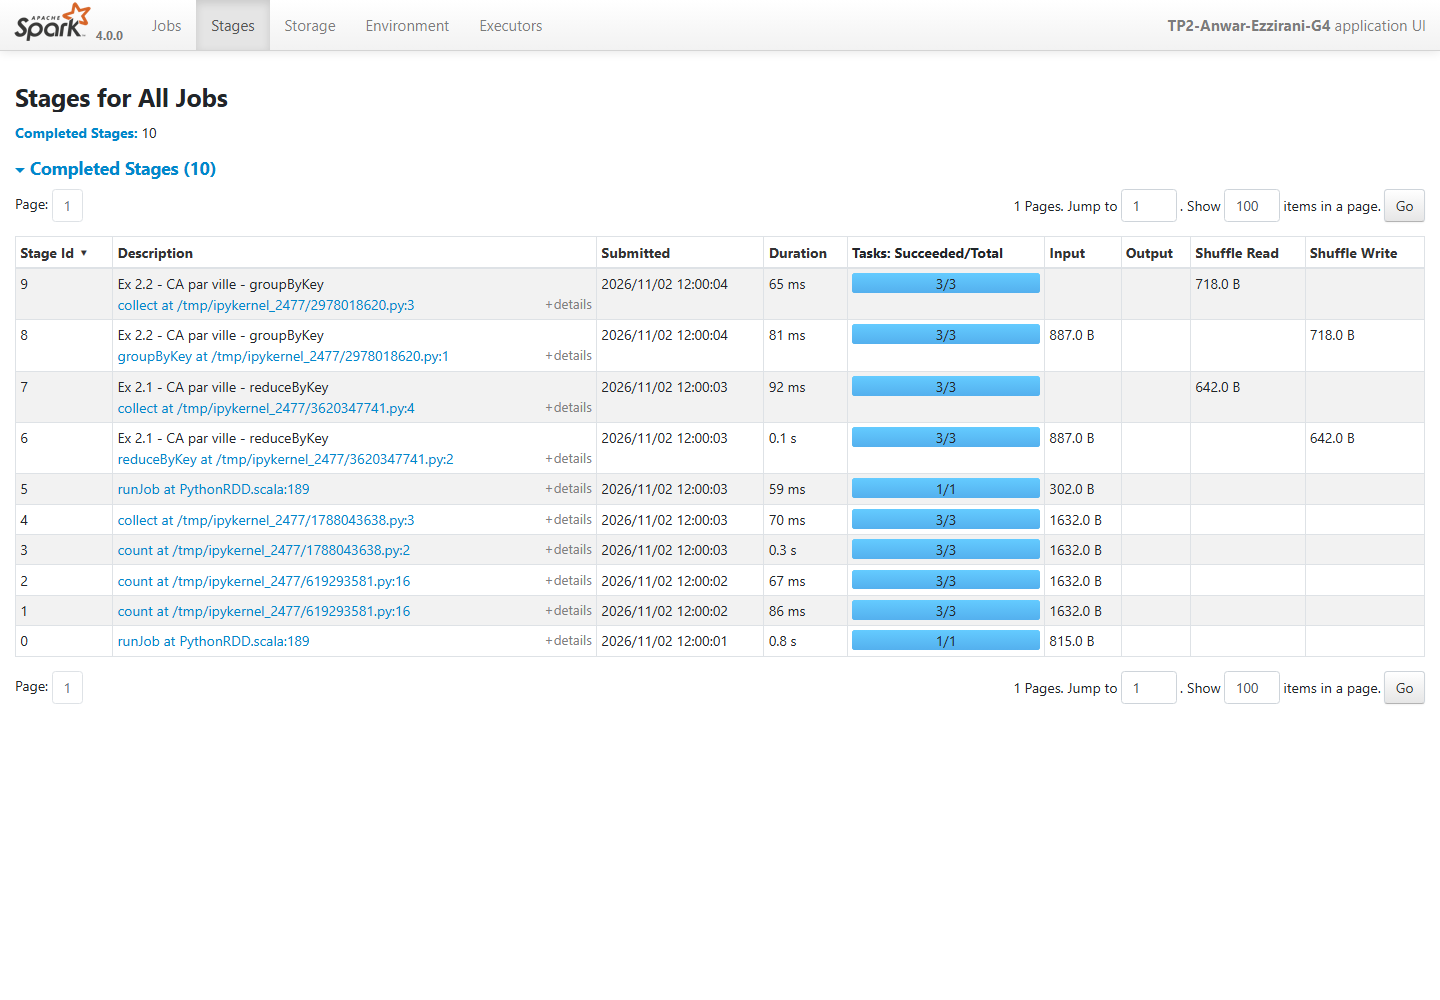

**Stage de shuffle — reduceByKey**

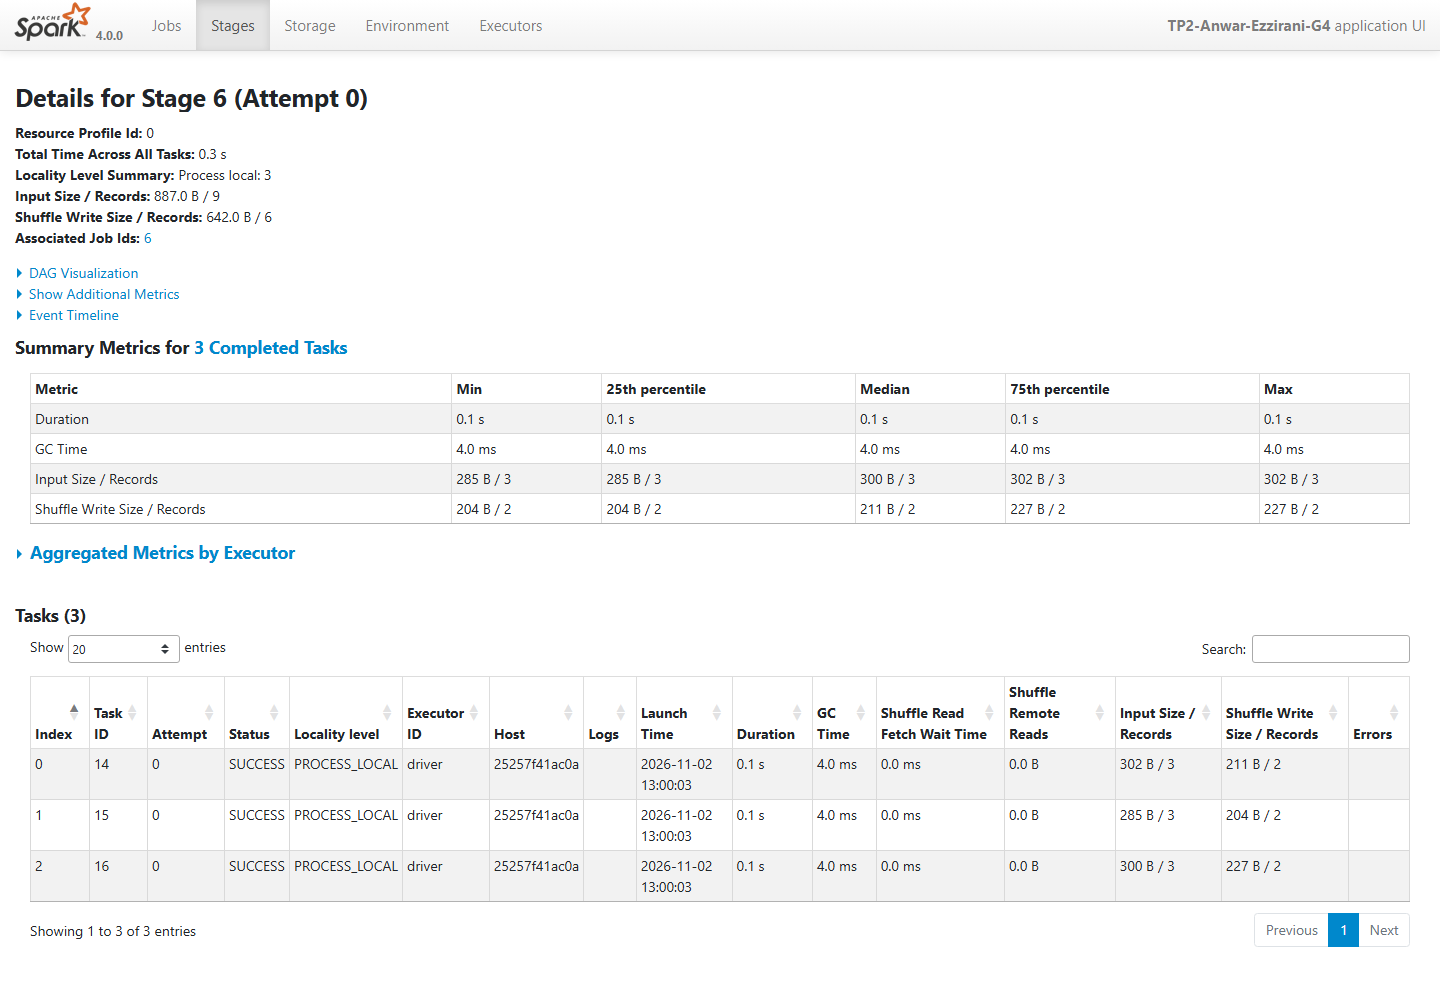

**Stage de shuffle — groupByKey**

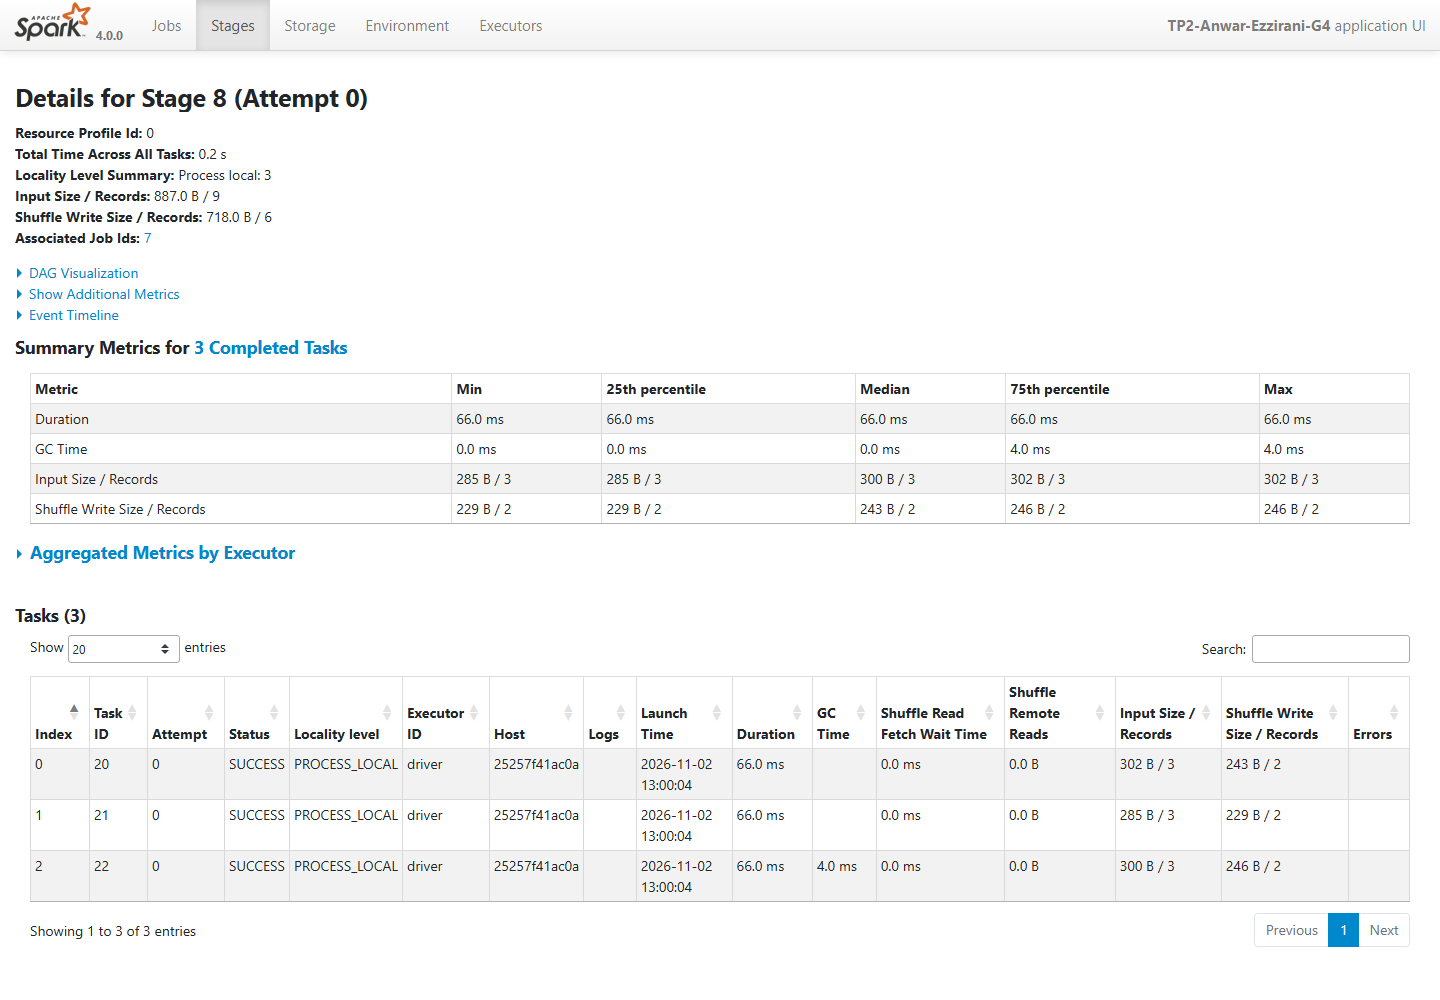

**Onglet Storage — RDD ventes_nettoyees matérialisé**

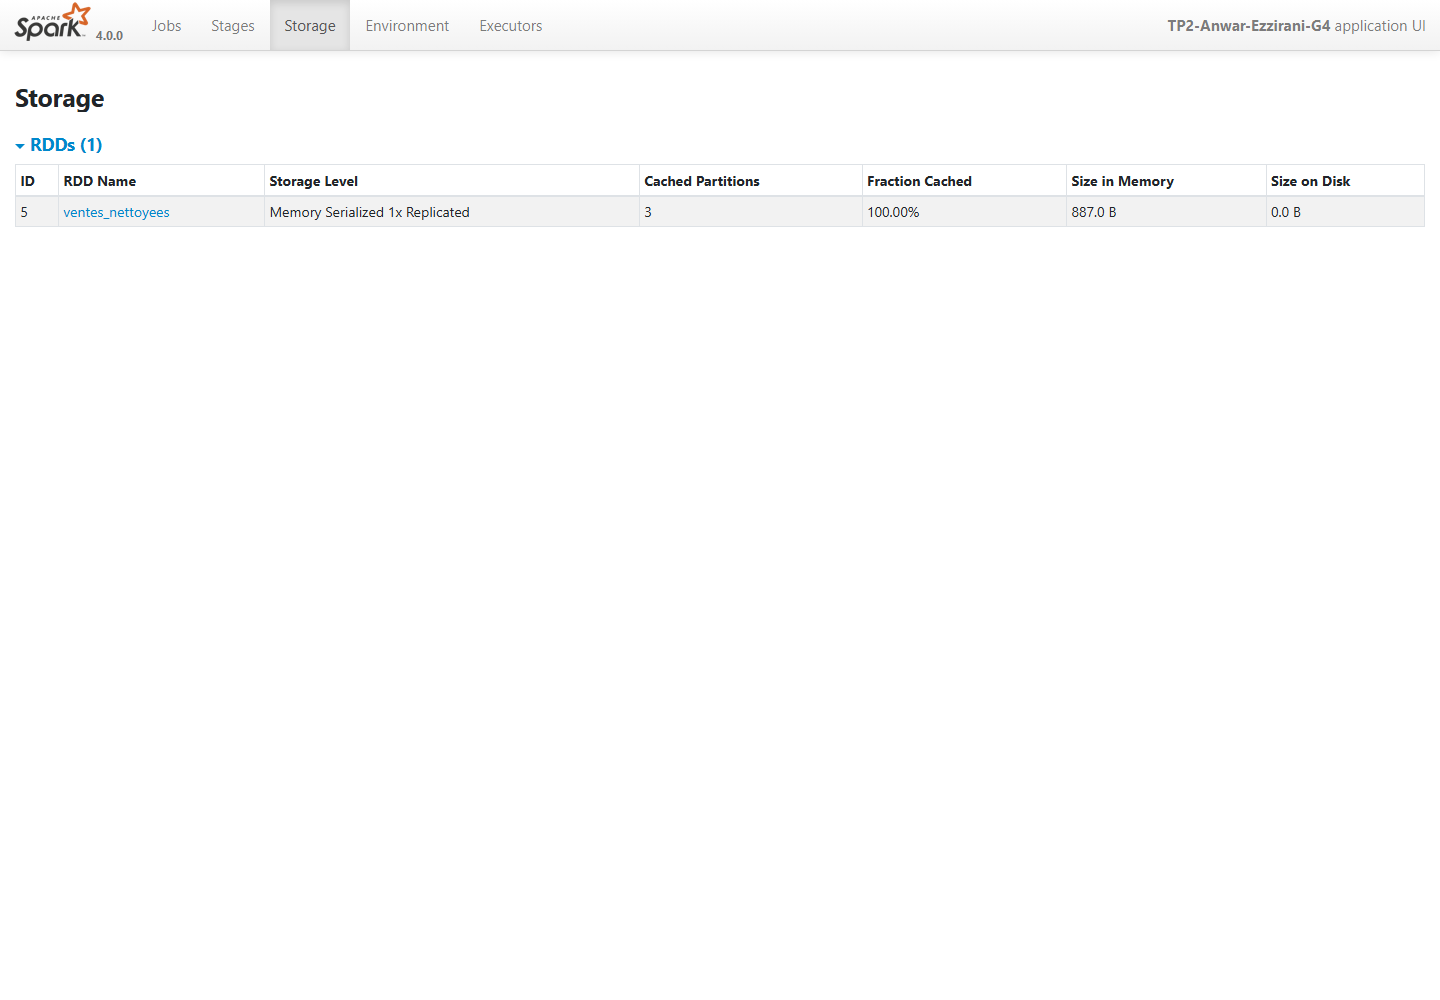

In [7]:
# Coordination avec le script de capture du navigateur, sans modifier les résultats.
if os.environ.get("TP2_CAPTURE") == "1":
    request = {"ui": sc.uiWebUrl, "mesures": mesures}
    (ART / "capture_request.json").write_text(json.dumps(request), encoding="utf-8")
    deadline = time.monotonic() + 120
    while not (ART / "capture_done.json").exists():
        if time.monotonic() > deadline:
            raise TimeoutError("Les captures de Spark UI n'ont pas été reçues.")
        time.sleep(1)
captures = [("stages.png", "Onglet Stages — comparaison des jobs 2.1 et 2.2"),
            ("reduce_stage.png", "Stage de shuffle — reduceByKey"),
            ("group_stage.png", "Stage de shuffle — groupByKey"),
            ("storage.png", "Onglet Storage — RDD ventes_nettoyees matérialisé")]
for fichier, legende in captures:
    chemin = CAP / fichier
    if chemin.exists():
        display(Markdown("**" + legende + "**"))
        display(Image(filename=str(chemin), width=1000))
    else:
        print("Capture conservée dans le livrable initial :", fichier)

### Ex. 2.3 — Nombre de ventes par ville
**Prévision.** Casablanca et Fès : 4 ventes chacune ; Rabat : 5 ; Agadir et Marrakech : 3.
`countByKey()` renvoie une structure locale sur le driver, pas un RDD.
Un très grand nombre de clés peut saturer sa mémoire ; utiliser alors une agrégation distribuée.

In [8]:
comptes = ca.countByKey()
print("Type :", type(comptes).__name__)
print(dict(sorted(comptes.items())))
assert dict(comptes) == {"Agadir":3, "Casablanca":4, "Fes":4, "Marrakech":3, "Rabat":5}

Type : defaultdict
{'Agadir': 3, 'Casablanca': 4, 'Fes': 4, 'Marrakech': 3, 'Rabat': 5}


### Ex. 2.4 — Maximum par produit avec `aggregateByKey`
**Prévision.** Clavier : 12 ; Laptop : 2 ; Souris : 30 ; Tablette : 6 ; Telephone : 5.
Le zéro initialise chaque agrégat ; le premier `max` combine dans une partition,
le second combine les agrégats des partitions. Zéro convient ici aux quantités positives ;
pour des données pouvant être négatives, il faudrait une autre valeur neutre.

In [9]:
max_quantites = ventes.map(lambda v: (v[3], v[4])).aggregateByKey(0, max, max)
print(sorted(max_quantites.collect()))
assert dict(max_quantites.collect()) == {"Clavier":12,"Laptop":2,"Souris":30,"Tablette":6,"Telephone":5}

[('Clavier', 12), ('Laptop', 2), ('Souris', 30), ('Tablette', 6), ('Telephone', 5)]


### Ex. 2.5 — Conversion avec `mapValues`
**Prévision.** Les cinq villes et les partitions restent identiques.
`mapValues` modifie seulement la valeur et conserve aussi le partitionneur du RDD clé/valeur,
contrairement à un `map` général. Le taux de 0,092 est celui imposé par le TP.

In [10]:
ca_euros = ca_ville.mapValues(lambda montant: montant * 0.092)
for ville, montant in sorted(ca_euros.collect()):
    print(f"{ville:12s} {montant:,.2f} EUR")
print("Éléments :", ca_ville.count(), "->", ca_euros.count())
print("Partitions :", ca_ville.getNumPartitions(), "->", ca_euros.getNumPartitions())
print("Partitionneur conservé :", ca_ville.partitioner == ca_euros.partitioner)
assert ca_ville.count() == ca_euros.count() == 5
assert ca_ville.getNumPartitions() == ca_euros.getNumPartitions()
assert ca_ville.partitioner == ca_euros.partitioner

Agadir       1,288.00 EUR
Casablanca   3,128.00 EUR
Fes          3,224.60 EUR
Marrakech    4,471.20 EUR
Rabat        3,873.20 EUR
Éléments : 5 -> 5
Partitions : 3 -> 3
Partitionneur conservé : True


### Ex. 2.6 — Deux tris décroissants
**Prévision.** Marrakech, Rabat, Fès, Casablanca, Agadir.
`sortBy` trie sur la valeur ; pour `sortByKey`, on inverse les couples avant de les trier.

In [11]:
tri_valeur = ca_ville.sortBy(lambda p: p[1], ascending=False).collect()
tri_cle = (ca_ville.map(lambda p: (p[1], p[0])).sortByKey(ascending=False)
           .map(lambda p: (p[1], p[0])).collect())
print("sortBy :", tri_valeur)
print("sortByKey :", tri_cle)
assert tri_valeur == tri_cle

sortBy : [('Marrakech', 48600.0), ('Rabat', 42100.0), ('Fes', 35050.0), ('Casablanca', 34000.0), ('Agadir', 14000.0)]
sortByKey : [('Marrakech', 48600.0), ('Rabat', 42100.0), ('Fes', 35050.0), ('Casablanca', 34000.0), ('Agadir', 14000.0)]


### Ex. 2.7 — Panier moyen en une agrégation
**Prévision.** La moyenne par ville est calculée par somme et effectif, puis division.
Marrakech : 16 200 MAD ; Fès : 8 762,50 ; Rabat : 8 420 ; Casablanca : 8 500 ; Agadir : 4 666,67.
L'agrégation de paires `(montant, 1)` évite une jointure entre deux calculs séparés.

In [12]:
paniers = (ventes.map(lambda v: (v[2], (v[4] * v[5], 1)))
           .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
           .mapValues(lambda p: p[0] / p[1]))
for ville, moyenne in sorted(paniers.collect()):
    print(f"{ville:12s} {moyenne:,.2f} MAD/vente")
RESULTATS["panier_moyen"] = dict(paniers.collect())

Agadir       4,666.67 MAD/vente
Casablanca   8,500.00 MAD/vente
Fes          8,762.50 MAD/vente
Marrakech    16,200.00 MAD/vente
Rabat        8,420.00 MAD/vente


## Partie 3 — Jointures
### Ex. 3.1 — Jointure interne
**Prévision.** Seules Casablanca, Fès et Rabat apparaissent. Agadir et Marrakech
n'ont pas de région dans le référentiel. Tanger a une région mais aucune vente.

In [13]:
regions = sc.parallelize([
    ("Casablanca", "Casablanca-Settat"), ("Rabat", "Rabat-Sale-Kenitra"),
    ("Fes", "Fes-Meknes"), ("Tanger", "Tanger-Tetouan")], 2)
interne = ca_ville.join(regions)
print(*sorted(interne.collect()), sep="\n")
assert set(interne.keys().collect()) == {"Casablanca", "Fes", "Rabat"}

('Casablanca', (34000.0, 'Casablanca-Settat'))
('Fes', (35050.0, 'Fes-Meknes'))
('Rabat', (42100.0, 'Rabat-Sale-Kenitra'))


### Ex. 3.2 — Jointures externes
**Prévision.** `leftOuterJoin` conserve les cinq villes vendeuses : `None` remplace
la région d'Agadir et de Marrakech. `rightOuterJoin` conserve les quatre villes du
référentiel : le CA de Tanger vaut `None` (absence de correspondance, pas un CA observé de zéro).

In [14]:
gauche = ca_ville.leftOuterJoin(regions)
droite = ca_ville.rightOuterJoin(regions)
print("LEFT OUTER JOIN :")
print(*sorted(gauche.collect()), sep="\n")
print("\nRIGHT OUTER JOIN :")
print(*sorted(droite.collect()), sep="\n")
assert gauche.count() == 5 and droite.count() == 4

LEFT OUTER JOIN :


('Agadir', (14000.0, None))
('Casablanca', (34000.0, 'Casablanca-Settat'))
('Fes', (35050.0, 'Fes-Meknes'))
('Marrakech', (48600.0, None))
('Rabat', (42100.0, 'Rabat-Sale-Kenitra'))

RIGHT OUTER JOIN :


('Casablanca', (34000.0, 'Casablanca-Settat'))
('Fes', (35050.0, 'Fes-Meknes'))
('Rabat', (42100.0, 'Rabat-Sale-Kenitra'))
('Tanger', (None, 'Tanger-Tetouan'))


### Ex. 3.3 et 3.4 — `cogroup` et choix de jointure
**Prévision.** `cogroup` contient six clés : les cinq villes vendeuses plus Tanger.
Les côtés sans correspondance sont des listes vides.
Pour un rapport de toutes les villes vendeuses enrichies de leur région si connue,
on choisit `ca_ville.leftOuterJoin(regions)`.

In [15]:
regroupement = ca_ville.cogroup(regions).mapValues(lambda p: (list(p[0]), list(p[1])))
print(*sorted(regroupement.collect()), sep="\n")
nb_union = ca_ville.keys().union(regions.keys()).distinct().count()
print("Clés cogroup :", regroupement.count(), "| Clés distinctes de l'union :", nb_union)
assert regroupement.count() == nb_union == 6

('Agadir', ([14000.0], []))
('Casablanca', ([34000.0], ['Casablanca-Settat']))
('Fes', ([35050.0], ['Fes-Meknes']))
('Marrakech', ([48600.0], []))
('Rabat', ([42100.0], ['Rabat-Sale-Kenitra']))
('Tanger', ([], ['Tanger-Tetouan']))


Clés cogroup : 6 | Clés distinctes de l'union : 6


## Partie 4 — Opérations ensemblistes et combinaisons
### Ex. 4.1 — Produits de Casablanca et Rabat
**Prévision.** Casablanca vend Clavier, Laptop, Souris et Telephone ; Rabat vend Laptop,
Souris, Tablette et Telephone. L'union contient cinq produits, l'intersection trois et
la différence seulement Clavier. La vente de Tablette à Casablanca est invalide.
`union` conserve normalement les doublons : `distinct()` est donc indispensable ici.

In [16]:
pc = ventes.filter(lambda v: v[2] == "Casablanca").map(lambda v: v[3]).distinct()
pr = ventes.filter(lambda v: v[2] == "Rabat").map(lambda v: v[3]).distinct()
union_produits = sorted(pc.union(pr).distinct().collect())
intersection = sorted(pc.intersection(pr).collect())
difference = sorted(pc.subtract(pr).collect())
print("Casablanca :", sorted(pc.collect()))
print("Rabat :", sorted(pr.collect()))
print("Union sans doublons :", union_produits)
print("Intersection :", intersection)
print("Casablanca moins Rabat :", difference)
assert len(union_produits) == 5 and len(intersection) == 3 and difference == ["Clavier"]

Casablanca : ['Clavier', 'Laptop', 'Souris', 'Telephone']
Rabat : ['Laptop', 'Souris', 'Tablette', 'Telephone']
Union sans doublons : ['Clavier', 'Laptop', 'Souris', 'Tablette', 'Telephone']
Intersection : ['Laptop', 'Souris', 'Telephone']
Casablanca moins Rabat : ['Clavier']


### Ex. 4.2 — Produit cartésien
**Prévision.** 5 villes × 5 produits = 25 couples, y compris ceux qui ne correspondent
à aucune vente observée. La taille croît comme le produit des cardinalités ; sur deux grands
RDD, le volume de calcul et de stockage peut devenir prohibitif.

In [17]:
villes = ventes.map(lambda v: v[2]).distinct()
produits = ventes.map(lambda v: v[3]).distinct()
cartesien = villes.cartesian(produits)
print("Villes :", villes.count(), "| Produits :", produits.count(), "| Couples :", cartesien.count())
print(*sorted(cartesien.collect()), sep="\n")
assert cartesien.count() == villes.count() * produits.count() == 25

Villes : 5 | Produits : 5 | Couples : 25


('Agadir', 'Clavier')
('Agadir', 'Laptop')
('Agadir', 'Souris')
('Agadir', 'Tablette')
('Agadir', 'Telephone')
('Casablanca', 'Clavier')
('Casablanca', 'Laptop')
('Casablanca', 'Souris')
('Casablanca', 'Tablette')
('Casablanca', 'Telephone')
('Fes', 'Clavier')
('Fes', 'Laptop')
('Fes', 'Souris')
('Fes', 'Tablette')
('Fes', 'Telephone')
('Marrakech', 'Clavier')
('Marrakech', 'Laptop')
('Marrakech', 'Souris')
('Marrakech', 'Tablette')
('Marrakech', 'Telephone')
('Rabat', 'Clavier')
('Rabat', 'Laptop')
('Rabat', 'Souris')
('Rabat', 'Tablette')
('Rabat', 'Telephone')


### Ex. 4.3 — `zip`, erreurs attendues et alternative
**Prévision.** Le cas valide donne `(1,11)` à `(5,15)`.
`zip` exige le même nombre de partitions ET le même nombre d'éléments dans chaque paire
de partitions. Trois partitions provoquent une erreur de structure ; six éléments sur deux
partitions provoquent une erreur lors de l'action.
`zipWithIndex` puis une jointure sur l'index permet de faire correspondre les positions
avec des partitionnements différents. La jointure interne ne garde que les indices communs ;
un `fullOuterJoin` serait nécessaire pour conserver aussi les éléments sans partenaire.

In [18]:
a = sc.parallelize(range(1, 6), 2)
b = sc.parallelize(range(11, 16), 2)
print("zip valide :", a.zip(b).collect())
erreurs_zip = []
for etiquette, autre in [("3 partitions", sc.parallelize(range(11, 16), 3)),
                         ("6 éléments / 2 partitions", sc.parallelize(range(11, 17), 2))]:
    try:
        a.zip(autre).collect()
    except Exception as exc:
        message = str(exc)
        pertinent = next((l.strip() for l in message.splitlines()
                          if "same number" in l or "Can only zip" in l), message.splitlines()[0])
        erreurs_zip.append({"cas": etiquette, "type": type(exc).__name__, "message": pertinent})
        print(f"Erreur attendue ({etiquette}) : {type(exc).__name__} — {pertinent}")
    else:
        raise AssertionError("Une erreur zip était attendue")
autre = sc.parallelize(range(11, 17), 3)
alternative = (a.zipWithIndex().map(lambda p: (p[1], p[0]))
               .join(autre.zipWithIndex().map(lambda p: (p[1], p[0])))
               .sortByKey().values().collect())
print("Alternative par index :", alternative)
RESULTATS["erreurs_zip"] = erreurs_zip
assert len(erreurs_zip) == 2 and alternative == [(1,11),(2,12),(3,13),(4,14),(5,15)]

zip valide : [(1, 11), (2, 12), (3, 13), (4, 14), (5, 15)]
Erreur attendue (3 partitions) : ValueError — Can only zip with RDD which has the same number of partitions
Erreur attendue (6 éléments / 2 partitions) : ValueError — Can not deserialize PairRDD with different number of items in batches: (2, 3)


Alternative par index : [(1, 11), (2, 12), (3, 13), (4, 14), (5, 15)]


## Partie 5 — Partitionnement et sauvegarde
### Ex. 5.1 et 5.2 — `coalesce` et `repartition`
**Prévision.** Lecture : trois partitions ; `coalesce(1)` : une ; `repartition(6)` : six ;
`coalesce(10)` : toujours trois. Sans shuffle, `coalesce` peut réduire mais ne peut pas
augmenter le nombre de partitions. `repartition(2)` implique un shuffle de redistribution.

In [19]:
partitionnements = {"initial": ventes.getNumPartitions(),
                   "coalesce(1)": ventes.coalesce(1).getNumPartitions(),
                   "repartition(6)": ventes.repartition(6).getNumPartitions(),
                   "coalesce(10)": ventes.coalesce(10).getNumPartitions()}
print(partitionnements)
print("\nPLAN coalesce(1) :\n", ventes.coalesce(1).toDebugString().decode())
print("\nPLAN repartition(2) :\n", ventes.repartition(2).toDebugString().decode())
RESULTATS["partitions"] = partitionnements
assert partitionnements == {"initial":3,"coalesce(1)":1,"repartition(6)":6,"coalesce(10)":3}

{'initial': 3, 'coalesce(1)': 1, 'repartition(6)': 6, 'coalesce(10)': 3}

PLAN coalesce(1) :
 (1) CoalescedRDD[179] at coalesce at NativeMethodAccessorImpl.java:0 []
 |  ventes_nettoyees PythonRDD[5] at RDD at PythonRDD.scala:56 []
 |      CachedPartitions: 3; MemorySize: 887.0 B; DiskSize: 0.0 B
 |  /home/jovyan/work/data/ventes.csv MapPartitionsRDD[1] at textFile at NativeMethodAccessorImpl.java:0 []
 |  /home/jovyan/work/data/ventes.csv HadoopRDD[0] at textFile at NativeMethodAccessorImpl.java:0 []

PLAN repartition(2) :
 (2) MapPartitionsRDD[184] at coalesce at NativeMethodAccessorImpl.java:0 []
 |  CoalescedRDD[183] at coalesce at NativeMethodAccessorImpl.java:0 []
 |  ShuffledRDD[182] at coalesce at NativeMethodAccessorImpl.java:0 []
 +-(3) MapPartitionsRDD[181] at coalesce at NativeMethodAccessorImpl.java:0 []
    |  PythonRDD[180] at RDD at PythonRDD.scala:56 []
    |  ventes_nettoyees PythonRDD[5] at RDD at PythonRDD.scala:56 []
    |      CachedPartitions: 3; MemorySize: 887.

### Ex. 5.3 — Écriture et relecture
**Prévision.** `saveAsTextFile` crée un dossier avec un seul fichier `part-*`, un marqueur
`_SUCCESS` vide et éventuellement des fichiers de contrôle. `_SUCCESS` indique la fin correcte
de l'écriture ; il ne contient aucune donnée. Le fichier texte contient les représentations des
tuples, sans schéma CSV. Un dossier déjà existant est refusé par Spark ; à la réexécution,
on conserve donc l'ancienne sortie et on utilise un nouveau nom.

In [20]:
sortie = DATA / "ca_ville"
if sortie.exists():
    from uuid import uuid4
    sortie = DATA / ("ca_ville_" + uuid4().hex[:8])
ca_ville.coalesce(1).saveAsTextFile(str(sortie))
print("Dossier :", sortie.name)
print("Fichiers :", sorted(os.listdir(sortie)))
print("Taille de _SUCCESS :", (sortie / "_SUCCESS").stat().st_size, "octet")
relues = sc.textFile(str(sortie)).collect()
print("Relecture :", sorted(relues))
assert len(list(sortie.glob("part-*"))) == 1
assert (sortie / "_SUCCESS").read_bytes() == b"" and len(relues) == 5

Dossier : ca_ville_048b8b6f
Fichiers : ['._SUCCESS.crc', '.part-00000.crc', '_SUCCESS', 'part-00000']
Taille de _SUCCESS : 0 octet
Relecture : ["('Agadir', 14000.0)", "('Casablanca', 34000.0)", "('Fes', 35050.0)", "('Marrakech', 48600.0)", "('Rabat', 42100.0)"]


## Partie 6 — Analyses métier
Chaque réponse utilise une chaîne de transformations terminée par une action.
L'exercice 6.4 comporte, conformément à l'énoncé, une action préalable pour la moyenne.

### Q6.1 — Produit le plus vendu en quantité
**Prévision.** Souris : 65 unités (20 + 15 + 30).

In [21]:
q61 = (ventes.map(lambda v: (v[3], v[4])).reduceByKey(add)
       .takeOrdered(1, key=lambda p: (-p[1], p[0])))
print("Produit le plus vendu :", q61)
RESULTATS["q61"] = q61
assert q61 == [("Souris", 65)]

Produit le plus vendu : [('Souris', 65)]


### Q6.2 — Ville au montant moyen le plus élevé
**Prévision.** Marrakech : 48 600 / 3 = 16 200 MAD par vente.

In [22]:
q62 = (ventes.map(lambda v: (v[2], (v[4] * v[5], 1)))
       .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
       .mapValues(lambda p: p[0] / p[1])
       .takeOrdered(1, key=lambda p: (-p[1], p[0])))
print("Ville au panier moyen maximal :", q62)
RESULTATS["q62"] = q62
assert q62 == [("Marrakech", 16200.0)]

Ville au panier moyen maximal : [('Marrakech', 16200.0)]


### Q6.3 — Villes triées et sans doublon par produit
**Prévision.** Laptop apparaît dans les cinq villes. Les ensembles sont fusionnés
par clé, puis convertis en listes triées. Cela évite de conserver des doublons intermédiaires.

In [23]:
q63 = (ventes.map(lambda v: (v[3], {v[2]}))
       .reduceByKey(lambda a, b: a | b).mapValues(sorted).sortByKey().collect())
print(*q63, sep="\n")
RESULTATS["q63"] = q63
assert dict(q63)["Laptop"] == ["Agadir", "Casablanca", "Fes", "Marrakech", "Rabat"]

('Clavier', ['Agadir', 'Casablanca', 'Fes'])
('Laptop', ['Agadir', 'Casablanca', 'Fes', 'Marrakech', 'Rabat'])
('Souris', ['Casablanca', 'Fes', 'Rabat'])
('Tablette', ['Fes', 'Marrakech', 'Rabat'])
('Telephone', ['Casablanca', 'Marrakech', 'Rabat'])


### Q6.4 — Ventes supérieures à la moyenne globale
**Prévision.** Le seuil est le CA global divisé par les 19 lignes valides.
La condition est strictement `>` ; elle compare le montant d'une vente, pas son prix unitaire.
La moyenne est calculée par une action avant le pipeline de filtrage.

In [24]:
moyenne_globale = ventes.map(lambda v: v[4] * v[5]).mean()
q64 = (ventes.filter(lambda v: v[4] * v[5] > moyenne_globale)
       .map(lambda v: v[0]).sortBy(lambda ident: ident).collect())
print(f"Moyenne globale : {moyenne_globale:,.6f} MAD")
print("Identifiants strictement au-dessus :", q64)
RESULTATS["moyenne_globale"] = moyenne_globale
RESULTATS["q64"] = q64

Moyenne globale : 9,144.736842 MAD
Identifiants strictement au-dessus : [1, 2, 3, 4, 5, 6, 8, 9, 18, 21]


### Q6.5 — Chiffre d'affaires par mois
**Prévision.** Les deux clés sont `2025-01` et `2025-02`. La somme des CA mensuels
doit être égale à la somme des CA par ville.

In [25]:
q65 = (ventes.map(lambda v: (v[1][:7], v[4] * v[5]))
       .reduceByKey(add).sortByKey().collect())
for mois, montant in q65:
    print(f"{mois} : {montant:,.2f} MAD")
RESULTATS["q65"] = q65
assert sum(m for _, m in q65) == sum(m for _, m in ca_resultat)

2025-01 : 129,200.00 MAD
2025-02 : 44,550.00 MAD


## Visualisation des résultats exécutés
Les graphiques suivants sont construits à partir des résultats Spark collectés,
sans ressaisie des montants.

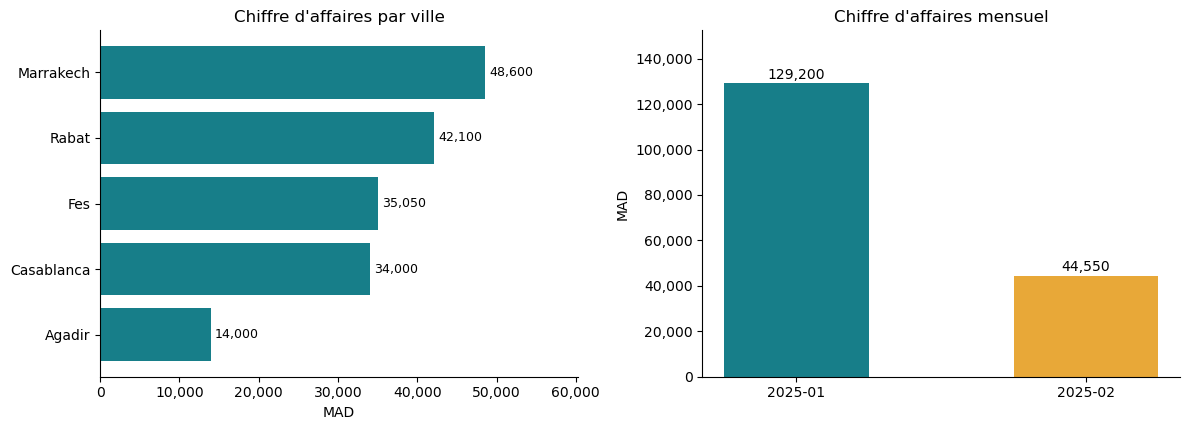

In [26]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":10})
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
classement = sorted(ca_resultat, key=lambda p: p[1])
axes[0].barh([p[0] for p in classement], [p[1] for p in classement], color="#177e89")
axes[0].set_title("Chiffre d'affaires par ville")
axes[0].set_xlabel("MAD")
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
for i, (_, valeur) in enumerate(classement):
    axes[0].text(valeur + 500, i, f"{valeur:,.0f}", va="center", fontsize=9)
axes[0].set_xlim(0, max(p[1] for p in classement) * 1.24)
axes[1].bar([p[0] for p in q65], [p[1] for p in q65], color=["#177e89", "#e8a838"], width=0.5)
axes[1].set_title("Chiffre d'affaires mensuel")
axes[1].set_ylabel("MAD")
axes[1].yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
for i, (_, valeur) in enumerate(q65):
    axes[1].text(i, valeur + 1800, f"{valeur:,.0f}", ha="center")
axes[1].set_ylim(0, max(p[1] for p in q65) * 1.18)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(ART / "resultats.png", dpi=180, bbox_inches="tight")
plt.show()

## Bilan et vérifications
La cellule finale compare les résultats Spark à une référence Python indépendante
construite depuis les 22 lignes du fichier d'entrée. Elle vérifie les agrégations, les
analyses métier et les identifiants sélectionnés, puis enregistre les résultats en JSON.
Les deux erreurs de `zip` sont les seules erreurs intentionnelles ; elles ont été interceptées.

In [27]:
from collections import defaultdict
import math
# Référence indépendante : conversion directe des lignes, sans appeler parse ou Spark.
reference = []
for ligne in lignes.splitlines()[1:]:
    champs = ligne.split(",")
    try:
        if len(champs) != 6:
            continue
        reference.append((int(champs[0]), champs[1], champs[2], champs[3], int(champs[4]), float(champs[5])))
    except ValueError:
        continue
ref_ca, ref_qte, ref_mois = defaultdict(float), defaultdict(int), defaultdict(float)
for ident, date, ville, produit, quantite, prix in reference:
    ref_ca[ville] += quantite * prix
    ref_qte[produit] += quantite
    ref_mois[date[:7]] += quantite * prix
ref_total = sum(ref_ca.values())
ref_moyenne = ref_total / len(reference)
ref_ids = sorted(v[0] for v in reference if v[4] * v[5] > ref_moyenne)
assert len(reference) == nb_valides
assert dict(ref_ca) == dict(ca_resultat)
assert sorted(ref_qte.items(), key=lambda p: (-p[1], p[0]))[:1] == q61
assert sorted(ref_mois.items()) == q65
assert math.isclose(ref_moyenne, moyenne_globale, rel_tol=1e-12)
assert ref_ids == q64
RESULTATS["total_ca"] = ref_total
RESULTATS["quantites_par_produit"] = dict(sorted(ref_qte.items()))
RESULTATS["validation"] = "Toutes les assertions Spark et la référence indépendante ont réussi."
(ART / "resultats.json").write_text(json.dumps(RESULTATS, ensure_ascii=False, indent=2), encoding="utf-8")
print("VALIDATION : toutes les vérifications ont réussi.")
print("Ventes valides :", nb_valides, "| Rejets :", len(rejets))
print(f"CA global : {ref_total:,.2f} MAD | Moyenne : {moyenne_globale:,.6f} MAD")
print("Produit dominant :", q61[0], "| Panier maximal :", q62[0])
print("Résultats enregistrés : artifacts/resultats.json")

VALIDATION : toutes les vérifications ont réussi.
Ventes valides : 19 | Rejets : 3
CA global : 173,750.00 MAD | Moyenne : 9,144.736842 MAD
Produit dominant : ('Souris', 65) | Panier maximal : ('Marrakech', 16200.0)
Résultats enregistrés : artifacts/resultats.json


## Références et reproduction
- Énoncé local : `TP2_RDD_Ventes.pdf`, pages 1 à 4.
- Documentation officielle Spark 4.0.0 : https://spark.apache.org/docs/4.0.0/
- API PySpark RDD : https://spark.apache.org/docs/4.0.0/api/python/reference/pyspark.html#rdd-apis
- Mesures de cette exécution : API REST Spark UI, `artifacts/shuffle_metrics.json` ;
  captures originales dans `artifacts/captures/` ; événements Spark dans `artifacts/spark-events/`.

Le notebook contient tous ses résultats et ses images. Pour le reproduire, ouvrir le
notebook dans JupyterLab avec Spark 4.0.0 et Java 17, puis exécuter toutes les cellules.
Les captures archivées correspondent à l'exécution de livraison ; leur régénération nécessite
le script de capture du navigateur fourni dans `scripts/`.